# 06 · Python: bibliotecas, tipos y conversión CSV → JSON

[Índice](00_indice_mqtt.ipynb) · [Siguiente](07_python_mqtt_clase_hilos_y_ack.ipynb)

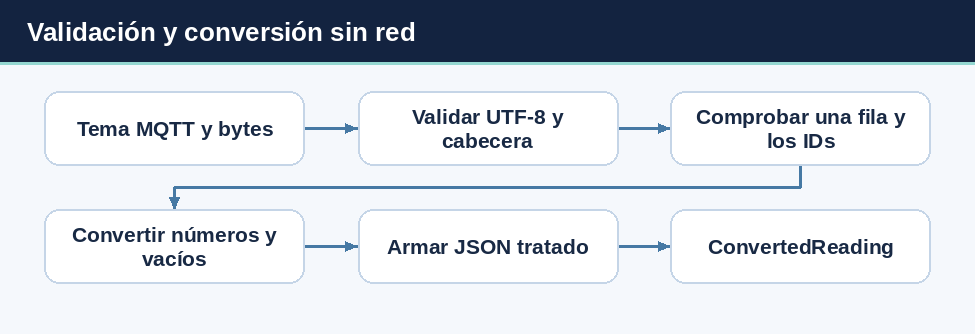

## Ubicación actual de los componentes

Este capítulo documenta `settings.py`, `models.py` y `converter.py`, dentro de
`backend/scripts/mqtt_bridge/`. `parse_arguments()` se explica ahora junto a `cli.py` en el
[notebook 07](07_python_mqtt_clase_hilos_y_ack.ipynb). `csv_to_json.py` ya no contiene
estas definiciones: es el punto de entrada.

| Módulo | Imports y elementos propios |
|---|---|
| `settings` | Constantes de transporte y contrato CSV/JSON. No importa otros módulos. |
| `models` | `dataclass` y `ConvertedReading`. |
| `converter` | `annotations`, `csv`, `io`, `json`, `math`; importa `ConvertedReading`, `CSV_COLUMNS` y `MEASUREMENT_FIELDS`. |
| `bridge` | `logging`, `queue`, `threading`, `csv`, `TYPE_CHECKING`; contiene `LOGGER`. |
| `cli` | `argparse`, `logging`, `CsvMqttBridge`, `MQTT_KEEPALIVE_SECONDS`; carga Paho en `main()`. |

## Bibliotecas Python

| Import | Función en el script | ¿Instalación extra? |
|---|---|---|
| `__future__.annotations` | Pospone la evaluación de anotaciones, útil para referirse a `mqtt.Client` sin importarlo al cargar el módulo. | No |
| `argparse` | Argumentos `--host` y `--port`. | No |
| `csv` | Lector CSV por nombres de columnas y errores de formato. | No |
| `io` | `StringIO`, adaptador de texto en memoria para el lector CSV. | No |
| `json` | Serialización del documento con `dumps`. | No |
| `logging` | Diagnósticos con niveles INFO/WARNING/ERROR. | No |
| `math` | `isfinite` para validar números. | No |
| `queue` | Cola segura entre hilos y excepción `Full`. | No |
| `threading` | Hilo trabajador separado del bucle MQTT. | No |
| `dataclasses.dataclass` | Genera inicializador y otros métodos de un contenedor de datos. | No |
| `typing.TYPE_CHECKING` | Importaciones destinadas al analizador de tipos, no al arranque normal. | No |
| `paho.mqtt.client` | Cliente MQTT, callbacks y confirmaciones QoS. | Sí, requirements.txt |

El código usa uniones como `float | None`; usa Python 3.10 o posterior para un entorno compatible
con esta sintaxis y herramientas. `import paho...` dentro de `main()` permite importar las funciones
de conversión para ejercicios sin tener Paho instalado. Esto no elimina la dependencia para ejecutar
la conexión real.

## Todas las constantes Python

| Nombre | Valor | Uso |
|---|---|---|
| `RAW_TOPIC_FILTER` | `dispositivo/+/crudo` | Suscripción a cualquier ID de un nivel. |
| `MESSAGE_QUEUE_SIZE` | 100 | Máximo de mensajes recibidos esperando en RAM. |
| `PUBLISH_TIMEOUT_SECONDS` | 10 | Límite de espera del PUBACK de una publicación procesada. |
| `MQTT_KEEPALIVE_SECONDS` | 60 | Intervalo configurado de mantenimiento de sesión MQTT. |
| `CSV_COLUMNS` | Tupla de siete nombres | Validación exacta de cabecera y orden. |
| `MEASUREMENT_FIELDS` | Tuplas nombre/sensor/unidad | Construcción uniforme de mediciones. |
| `LOGGER` | Logger de `bridge.py` | Emisión de diagnósticos; es una instancia, no vive en settings.py. |

En Python las MAYÚSCULAS son una convención: no prohíben reasignar una variable. Una tupla no
permite cambiar sus posiciones, pero eso no convierte en inmutable cualquier objeto que pudiera
contener. Las tuplas de este script contienen cadenas.

## Clase `ConvertedReading`

`@dataclass(frozen=True)` crea una clase de datos y restringe reasignación de sus campos.
`device_id: str` identifica placa; `record_id: str` identifica fila; `json_payload: str` conserva el
JSON serializado. Los tres se pasan por nombre al constructor. No valida automáticamente tipos
ni contenido: las comprobaciones están en `convert_csv_message`. Aquí todos sus campos son cadenas;
`frozen` no sería una garantía general de inmutabilidad profunda si contuviera colecciones mutables.

## Imports del conversor y dirección de dependencias

```python
from .models import ConvertedReading
from .settings import CSV_COLUMNS, MEASUREMENT_FIELDS
```

El punto significa «dentro de este paquete». El conversor recibe `topic: str` y
`payload: bytes`; devuelve `ConvertedReading` o levanta una excepción. No recibe
`mqtt.Client`, no publica mensajes y no necesita saber la IP del broker. Esto permite
usarlo en pruebas, en un notebook o desde otro programa sin abrir sockets.

`models` y `settings` no importan `converter`; por eso no hay una dependencia circular.
Cambiar el destino de publicación pertenece a `bridge`; cambiar las reglas del CSV
pertenece a `converter` y puede requerir coordinar cambios con el firmware.

```python
@dataclass(frozen=True)
class ConvertedReading:
    """Lectura convertida y datos necesarios para confirmar su procesamiento."""

    device_id: str
    record_id: str
    json_payload: str
```

## `parse_measurement`


**Parámetro:** `value: str`, campo CSV. **Retorno:** `float | None`.
Una cadena vacía devuelve `None`, que `json.dumps` convierte a null. Para texto no vacío llama a
`float(value)`; si no puede convertir, Python levanta `ValueError`. Rechaza explícitamente NaN e
infinitos con `math.isfinite(number)`.

No comprueba el rango físico de temperatura, humedad ni ppm: esta función valida representación
numérica finita. `"0"` sí se convierte a 0.0 y no se considera vacío.

```python
def parse_measurement(value: str) -> float | None:
    """Representa campos vacios como null y rechaza numeros no finitos."""
    if not value:
        return None

    number = float(value)
    if not math.isfinite(number):
        raise ValueError("Numero no finito")

    return number
```

## `convert_csv_message`


**Parámetros:** `topic: str`, topic completo recibido, y `payload: bytes`, contenido MQTT.
**Retorno:** una instancia `ConvertedReading`. Puede levantar errores de formato, Unicode o datos.

Divide topic con `split("/")` y exige tres niveles, prefijo dispositivo, ID no vacío y sufijo crudo.
Decodifica bytes con UTF-8 y crea `StringIO` para tratar el texto como un archivo. `csv.DictReader`
usa la cabecera como claves. `strict=True` activa errores del analizador; las comprobaciones propias
son las que exigen cabecera exacta, una fila y número correcto de columnas.

`reader.fieldnames != list(CSV_COLUMNS)` compara listas y orden. `rows=list(reader)` consume las
filas. `None in row` detecta una clave extra de DictReader para campos sobrantes; los valores None
detectan campos ausentes. El generador con `any` verifica si falta alguno. Luego verifica identidad
con el topic, presencia del ID del registro y calibrate limitado a `true` o `false` textuales.

Una comprensión de diccionario recorre MEASUREMENT_FIELDS y construye sensor/value/unit. El booleano
real resulta de `row["calibrate"] == "true"`. `row["timestamp"] or None` convierte vacío a None;
no valida que un timestamp no vacío tenga formato ISO ni que represente una fecha real.

`json.dumps(document, ensure_ascii=False, allow_nan=False)` devuelve texto, conserva ° sin escaparlo
obligatoriamente a Unicode y prohíbe NaN/Infinity. Los argumentos por nombre hacen explícitas las
opciones. El ID de fila queda fuera del JSON tratado y se conserva para el ACK.

```python
def convert_csv_message(topic: str, payload: bytes) -> ConvertedReading:
    """Valida una fila del CSV y genera el mismo esquema JSON del firmware."""
    topic_parts = topic.split("/")
    if (
        len(topic_parts) != 3
        or topic_parts[0] != "dispositivo"
        or not topic_parts[1]
        or topic_parts[2] != "crudo"
    ):
        raise ValueError("Topic no valido")

    reader = csv.DictReader(io.StringIO(payload.decode("utf-8")), strict=True)
    if reader.fieldnames != list(CSV_COLUMNS):
        raise ValueError("Cabecera CSV no valida")

    rows = list(reader)
    if len(rows) != 1:
        raise ValueError("Se espera una lectura por mensaje CSV")

    row = rows[0]
    if None in row or any(value is None for value in row.values()):
        raise ValueError("Cantidad de columnas CSV no valida")

    device_id = topic_parts[1]
    if row["device_id"] != device_id or not row["id"]:
        raise ValueError("ID no coincide con el topic o falta el ID del registro")
    if row["calibrate"] not in ("true", "false"):
        raise ValueError("calibrate invalido")

    measurements = {
        name: {
            "sensor": sensor,
            "value": parse_measurement(row[name]),
            "unit": unit,
        }
        for name, sensor, unit in MEASUREMENT_FIELDS
    }
    measurements["gas"]["calibrate"] = row["calibrate"] == "true"
    document = {
        "device_id": device_id,
        "timestamp": row["timestamp"] or None,
        "measurements": measurements,
    }

    return ConvertedReading(
        device_id=device_id,
        record_id=row["id"],
        json_payload=json.dumps(document, ensure_ascii=False, allow_nan=False),
    )
```

## Sintaxis Python que aparece en estas funciones

- `def name(parameter: Type) -> ReturnType`: anotaciones de tipos; no fuerzan validación en ejecución.
- `None`: ausencia de valor; equivale a JSON null al serializar, no a cadena vacía.
- `raise ValueError(...)`: detiene la operación y comunica al llamador que el dato no es válido.
- `for name, sensor, unit in ...`: desempaqueta cada tupla en tres variables.
- `{name: {...} for ...}`: comprensión que crea un diccionario, una entrada por medición.
- `any(value is None for value in row.values())`: generador evaluado hasta encontrar un verdadero.
- `is None`: identidad con el objeto None; `==` compara valores.
- `dict[key]`: consulta de un campo; puede levantar KeyError si falta.
- `f"dispositivo/{device_id}/tratado"`: f-string que interpola valores en texto.
- Docstring: primera cadena dentro de módulo, clase o función; documenta su propósito.

In [ ]:
# Ejercicio: diferencias entre datos Python y su representación JSON.
import json
import math

example = {"value": None, "calibrate": False, "unit": "°C"}
serialized = json.dumps(example, ensure_ascii=False, allow_nan=False)
assert json.loads(serialized) == example
assert math.isfinite(float("25.0"))
print(serialized)

[Índice](00_indice_mqtt.ipynb) · [Siguiente](07_python_mqtt_clase_hilos_y_ack.ipynb)